### Load libraries

In [1]:
# Basic libraries
import os, sys
from datetime import date
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd 
import numpy as np 
import scanpy as sc 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# DGE analysis
import pydeseq2
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import decoupler 

# GO analysis
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import gseapy as gp
from gseapy.plot import gseaplot

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")
res_dir = os.getenv("RESULTS_DIR")
ontology_dir  = os.getenv("ONTOLOGY_DIR")

### Load the data

In [3]:
# load pseudobulked adata
pdata = sc.read_h5ad(processed_adata_dir + "pdata_pseudobulked_RG_subclusters.h5ad")

In [4]:
# Subset to clusters of interest
rg2_hs_ncx_mm_ncx = pdata[(pdata.obs['leiden_subclustered_G1 RG'].isin(['RG 2', 'RG'])) & (pdata.obs['species'].isin(['human_ncx', 'mouse_ncx']))].copy()

In [5]:
# Store raw counts in layers
rg2_hs_ncx_mm_ncx.layers['counts'] = rg2_hs_ncx_mm_ncx.X.copy()
# Normalize, scale and compute pca
sc.pp.normalize_total(rg2_hs_ncx_mm_ncx, target_sum=1e6, exclude_highly_expressed=True)
rg2_hs_ncx_mm_ncx.layers['normalized'] = rg2_hs_ncx_mm_ncx.X.copy()
sc.pp.log1p(rg2_hs_ncx_mm_ncx)
rg2_hs_ncx_mm_ncx.layers['log-normalized'] = rg2_hs_ncx_mm_ncx.X.copy()
sc.pp.scale(rg2_hs_ncx_mm_ncx, max_value=10)
rg2_hs_ncx_mm_ncx.layers['normalized-scaled'] = rg2_hs_ncx_mm_ncx.X.copy()

8484


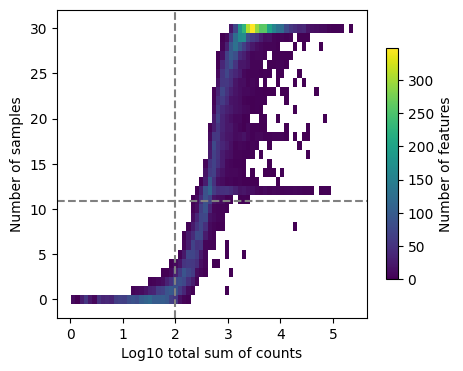

In [6]:
rg2_hs_ncx_mm_ncx.X = rg2_hs_ncx_mm_ncx.layers['normalized'].copy()
decoupler.plot_filter_by_expr(rg2_hs_ncx_mm_ncx, group='leiden_subclustered_G1 RG', min_count=15, min_total_count=100, min_prop = 0.7)
genes = decoupler.filter_by_expr(rg2_hs_ncx_mm_ncx, group='leiden_subclustered_G1 RG', min_count= 15, min_total_count=100)
print(len(genes))
# Subset
rg2_hs_ncx_mm_ncx_ss = rg2_hs_ncx_mm_ncx[:, genes].copy()

### DGE analysis

In [7]:
# Prepare the DeSeq2 format
rg2_hs_ncx_mm_ncx_ss.X = rg2_hs_ncx_mm_ncx_ss.layers['counts'].copy()

dds = DeseqDataSet(
    adata = rg2_hs_ncx_mm_ncx_ss,    
    design_factors= ['leiden_subclustered_G1 RG'],
    ref_level=['leiden_subclustered_G1 RG', 'RG 2'],
    refit_cooks=True)

/tmp/ipykernel_1503852/2360969183.py:4: UserWarning: Same factor names in the design contain underscores ('_'). They will
                be converted to hyphens ('-').
  dds = DeseqDataSet(


In [8]:
# Perform deseq2
dds.deseq2() 

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 3.32 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 3.33 seconds.

Fitting LFCs...
... done in 1.98 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 1 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.



In [9]:
# Output results
stat_res = DeseqStats(dds, contrast=['leiden-subclustered-G1 RG', 'RG 2', 'RG'])
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: leiden-subclustered-G1 RG RG 2 vs RG
         baseMean  log2FoldChange     lfcSE       stat        pvalue  \
AAAS     9.318005        0.688473  0.196851   3.497438  4.697491e-04   
AACS     6.684728        0.123282  0.246281   0.500578  6.166685e-01   
AAGAB    7.089792       -1.677329  0.252095  -6.653555  2.860971e-11   
AAK1     8.210295        4.232084  0.392486  10.782777  4.151596e-27   
AAMDC   20.368785        0.274593  0.207023   1.326393  1.847095e-01   
...           ...             ...       ...        ...           ...   
ZXDC     4.080860        1.689836  0.321456   5.256821  1.465670e-07   
ZYG11B  18.510040        0.858316  0.172290   4.981810  6.299235e-07   
ZYX     14.352516       -0.121936  0.193155  -0.631285  5.278541e-01   
ZZEF1    5.509013       -0.037683  0.275357  -0.136852  8.911475e-01   
ZZZ3    21.684728        0.220161  0.190148   1.157840  2.469293e-01   

                padj  
AAAS    8.391980e-04  
AACS    6.6284

... done in 0.68 seconds.



In [10]:
# Output the dataframe
results_df = stat_res.results_df
# Define background genes
background = results_df.dropna(subset=['padj'])
print(len(background))

8484


In [11]:
results_df = stat_res.results_df
# Reindex the dataframe
results_df_copy = results_df.copy()
results_df_copy.reset_index(inplace=True)
results_df_copy.rename(columns ={'index':'gene_name'}, inplace = True)

In [12]:
# Convert to -log10padj
results_df['log_10_padj'] = -np.log10(results_df['padj'])
# Cap the -log10padj
cap = 10
results_df['log_10_padj_capped'] = np.where(results_df['log_10_padj']>cap, cap, results_df['log_10_padj'])

In [13]:
# Filter the p adjusted 
DEGs = results_df[results_df['padj'] < 0.01]
# Filtr the log2FC
degs_human_up = DEGs[DEGs['log2FoldChange'] > 1]
degs_human_down = DEGs[DEGs['log2FoldChange'] < -1]
# Print the number of up and down-regulated genes
print(len(degs_human_up))
print(len(degs_human_down))

2643
1238


In [14]:
# save DEGs and background
degs_human_up.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_ncx_rg/DEGs_up_hs_ncx_rg2_vs_mm_ncx_rg_FULL.csv')
degs_human_down.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_ncx_rg/DEGs_down_hs_ncx_rg2_vs_mm_ncx_rg_FULL.csv')
background.to_csv(res_dir + 'degs/hs_ncx_rg2_vs_mm_ncx_rg/DEGs_background_hs_ncx_rg2_vs_mm_ncx_rg_FULL.csv')

In [15]:
degs_human_up_list = degs_human_up.reset_index()['index'].tolist()
degs_human_down_list = degs_human_down.reset_index()['index'].tolist()

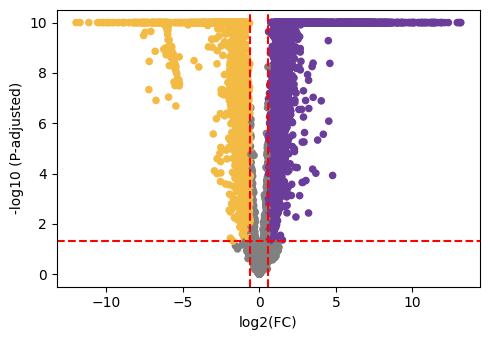

In [16]:
script_path = src_dir + 'Volcano_plot.py'
%run -i $script_path
# Plot the volcano plot
volcano_plot(df = results_df, df_up=degs_human_up, df_down=degs_human_down)
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/hs_ncx_rg2_vs_mm_ncx_rg/Volcano_plot_hs_ncx_rg2_vs_mm_ncx_rg_FULL.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/hs_ncx_rg2_vs_mm_ncx_rg/Volcano_plot_hs_ncx_rg2_vs_mm_ncx_rg_FULL.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

#### GO

In [17]:
# Intersect individual background lists 
background_list = results_df.reset_index()['index'].tolist()
print(len(background_list))

8484


In [18]:
# up-regulated genes
degs_up = degs_human_up.reset_index()['index'].tolist()
print(len(degs_up))

2643


In [19]:
# intersect down-regulated genes
degs_down = degs_human_down.reset_index()['index'].tolist()
print(len(degs_down))

1238


In [20]:
# Load the ontology lists
ontology_list = ontology_dir + 'msigdb/c5.go.bp.v2023.2.Hs.symbols.gmt'

In [21]:
# Perform GO analysis
# Intersected Up-regulated in hs-ncx-rg-2
hsNcx_vs_mmNcx_up = gp.enrichr(gene_list= degs_up, 
                                  gene_sets= ontology_list, 
                                  organism='Human', 
                                  cutoff=0.5, 
                                  background = background_list,
                                  no_plot= True)

hsNcx_vs_mmNcx_up_df = pd.DataFrame(hsNcx_vs_mmNcx_up.results)

# Down-regulated in human Ncx bRG 1 vs mouse DG bRG 1
hsNcx_vs_mmNcx_down = gp.enrichr(gene_list= degs_down, 
                                    gene_sets= ontology_list, 
                                    organism='Human', 
                                    cutoff=0.5, 
                                    background = background_list,
                                    no_plot= True)

hsNcx_vs_mmNcx_down_df = pd.DataFrame(hsNcx_vs_mmNcx_down.results)

In [22]:
# Save the files
# up-regulated GO terms
hsNcx_vs_mmNcx_up_df.to_csv(res_dir + 'GO/hs_ncx_rg2_vs_mm_ncx_rg/GO_hs_ncx_rg2_vs_mm_ncx_rg_UP_enrichment_FULL.csv')
# down-regulated GO terms
hsNcx_vs_mmNcx_down_df.to_csv(res_dir + 'GO/hs_ncx_rg2_vs_mm_ncx_rg/GO_hs_ncx_rg2_vs_mm_ncx_rg_DOWN_enrichment_FULL.csv')

In [23]:
# Define the 'Gene ontology type' 
hsNcx_vs_mmNcx_up_df['Ontology_type'] = hsNcx_vs_mmNcx_up_df.Gene_set.str[:8]
hsNcx_vs_mmNcx_down_df['Ontology_type'] = hsNcx_vs_mmNcx_down_df.Gene_set.str[:8]

In [24]:
# Add the 'regulation' column
hsNcx_vs_mmNcx_up_df['regulation'] = 'up-regulated'
hsNcx_vs_mmNcx_down_df['regulation'] = 'down-regulated'

In [25]:
# Remove the insignificant terms
hsNcx_vs_mmNcx_up_df_sig = hsNcx_vs_mmNcx_up_df[hsNcx_vs_mmNcx_up_df['Adjusted P-value'] < 0.05]
hsNcx_vs_mmNcx_down_df_sig = hsNcx_vs_mmNcx_down_df[hsNcx_vs_mmNcx_down_df['Adjusted P-value'] < 0.05]

In [26]:
# Sort based on the Combined Score
# up-regulated GO terms
hsNcx_vs_mmNcx_up_df_sig = hsNcx_vs_mmNcx_up_df_sig.sort_values(by = 'Combined Score', ascending=False)
# down-regulated GO terms
hsNcx_vs_mmNcx_down_df_sig = hsNcx_vs_mmNcx_down_df_sig.sort_values(by = 'Combined Score', ascending=False)

In [27]:
# Clean the 'Term' column 
# up-regulated GO terms
hsNcx_vs_mmNcx_up_df_sig['Term_clean'] = hsNcx_vs_mmNcx_up_df_sig.Term.apply(lambda x: x[5:])
hsNcx_vs_mmNcx_up_df_sig["Term_clean"] = hsNcx_vs_mmNcx_up_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()
# down-regulated GO terms
hsNcx_vs_mmNcx_down_df_sig['Term_clean'] = hsNcx_vs_mmNcx_down_df_sig.Term.apply(lambda x: x[5:])
hsNcx_vs_mmNcx_down_df_sig["Term_clean"] = hsNcx_vs_mmNcx_down_df_sig["Term_clean"].str.replace("_", " ").str.capitalize()

In [28]:
 # Subset the list of 'up-regulated' GO terms to terms of interest
# up-regulated terms
terms_of_interest_up = ['Neurogenesis', 'Cell adhesion', 'Synapse organization', 'Cell morphogenesis involved in neuron differentiation', 
                        'Cell motility', 'Cell projection organization', 'Cell morphogenesis', 'Cell part morphogenesis']

hsNcx_vs_mmNcx_up_df_sig_ss = hsNcx_vs_mmNcx_up_df_sig[hsNcx_vs_mmNcx_up_df_sig['Term_clean'].isin(terms_of_interest_up)]

# down-regulated terms
terms_of_interest_down = ['Dna metabolic process', 'Ncrna processing', 'Mitotic dna replication']

hsNcx_vs_mmNcx_down_df_sig_ss = hsNcx_vs_mmNcx_down_df_sig[hsNcx_vs_mmNcx_down_df_sig['Term_clean'].isin(terms_of_interest_down)]

In [29]:
# Concatenate 
hsNcx_vs_mmNcx_combined = pd.concat([hsNcx_vs_mmNcx_up_df_sig_ss, hsNcx_vs_mmNcx_down_df_sig_ss])

# Add negative 'Combined Scores' to down-regulated GO terms
hsNcx_vs_mmNcx_combined['Modified Combined Score'] = hsNcx_vs_mmNcx_combined.apply(lambda row: -row['Combined Score'] if 
                                                                                        row['regulation'] == 'down-regulated' else row['Combined Score'], axis = 1)

# Convert the Adjusted P-value to -log10 format
hsNcx_vs_mmNcx_combined['-log10(Adjusted P-value)'] = -np.log10(hsNcx_vs_mmNcx_combined['Adjusted P-value'])

In [30]:
# Sort values based on 'Modified Combined Score'
hsNcx_vs_mmNcx_combined = hsNcx_vs_mmNcx_combined.sort_values(by='Modified Combined Score', ascending=False)

/tmp/ipykernel_1503852/501546203.py:8: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


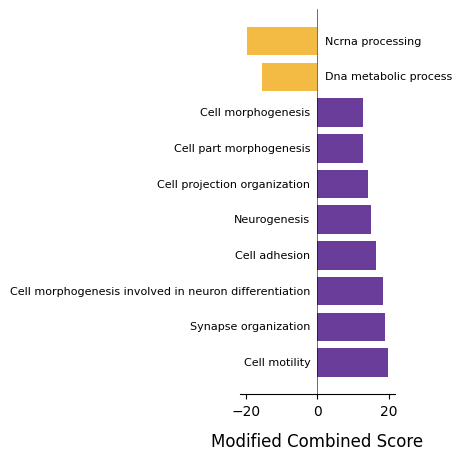

In [31]:
script_path = src_dir + 'GO_barplot.py'
%run -i $script_path
# Plot
GO_barplot(hsNcx_vs_mmNcx_combined, colorbar = False, distance = 'medium')
# Save the plot
#fig = plt.gcf()
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + "GO/hs_ncx_rg2_vs_mm_ncx_rg/Barplot_hs_ncx_rg2_vs_mm_ncx_rg_FULL_comparison.png", dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + "GO/hs_ncx_rg2_vs_mm_ncx_rg/Barplot_hs_ncx_rg2_vs_mm_ncx_rg_FULL_comparison.svg", dpi = 300, bbox_inches = 'tight')
plt.show()